# 02 · Modelling — baseline, improved model, imbalance, threshold, test
This notebook walks through the same steps as `python -m src.train`, using the same functions, so you can inspect every stage.

**Rules enforced:** all fitting uses *train only*; the threshold is chosen from *out-of-sample predictions on train + val* (never test); *test is evaluated once per run, only after every choice is frozen* (section 5). Section 3 runs a 60-iteration random search (~1 min).

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT   # works whether VS Code opens the folder or the notebook dir
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")

import json
from src import evaluate as ev
from src.config import RAW_FILE, COST_FN, COST_FP, THRESH_SMOOTH, N_BOOT
from src.data import load_raw, clean, split
from src.train import candidates, cv_compare, tune_xgb, clean_params, cost_sensitivity, pooled_predictions, BASELINE

df = clean(load_raw(RAW_FILE))
X_train, X_val, X_test, y_train, y_val, y_test = split(df)
spw = float((y_train == 0).sum() / (y_train == 1).sum())
print(f"train/val/test = {len(X_train)}/{len(X_val)}/{len(X_test)} | churn rate {y_train.mean():.3f} | neg/pos = {spw:.2f}")

train/val/test = 4225/1409/1409 | churn rate 0.265 | neg/pos = 2.77


## 1 · What goes into the model
All steps live in **one pipeline**, so the imputer / scaler / encoder / SMOTE are fit on training folds only.

In [2]:
cands = candidates(spw)
cands["XGBoost"]

,steps,"[('features', ...), ('prep', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...t 0x1147af920>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictionary of additional keyword arguments to pass to func... versionadded:: 0.18",None


## 2 · Baseline vs candidates and imbalance strategies (5-fold CV, train only)
Metric = **PR-AUC** (average precision). With ~26% positives it is more informative than accuracy or ROC-AUC.

,model,cv_pr_auc,cv_pr_auc_std,cv_roc_auc
0,XGBoost,0.6747,0.0123,0.8480
1,XGBoost + class weight,0.6727,0.0127,0.8472
2,Logistic Regression (baseline),0.6686,0.0222,0.8484
3,Logistic Regression + class_weight,0.6680,0.0226,0.8484
4,LightGBM + class weight,0.6652,0.0109,0.8430
5,LightGBM,0.6648,0.0086,0.8443
6,LightGBM + SMOTE,0.6629,0.0045,0.8437


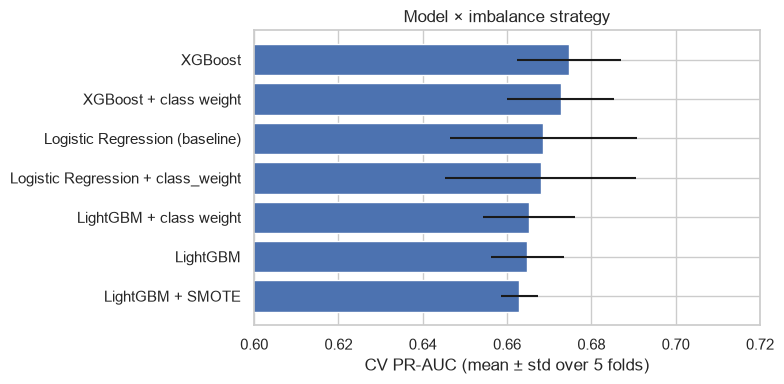

In [3]:
cv_table = cv_compare(cands, X_train, y_train, verbose=False)
display(cv_table.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
t = cv_table.iloc[::-1]
ax.barh(t["model"], t["cv_pr_auc"], xerr=t["cv_pr_auc_std"], color="#4C72B0")
ax.set_xlim(0.6, 0.72); ax.set_xlabel("CV PR-AUC (mean ± std over 5 folds)")
ax.set_title("Model × imbalance strategy"); plt.tight_layout(); plt.show()

**How to read this:** compare the *gaps* with the error bars. If a difference is smaller than the fold-to-fold std, it is noise, not a win. Check whether any imbalance technique (class weight, SMOTE) beats its un-weighted twin.

## 3 · Tune the improved model (XGBoost)
Random search over shallow trees + strong regularisation, scored by CV PR-AUC on train.

In [4]:
search = tune_xgb(X_train, y_train, n_iter=60)
print(f"best CV PR-AUC: {search.best_score_:.4f}")
print("best params:", clean_params(search.best_params_))

improved = search.best_estimator_
baseline = cands[BASELINE].fit(X_train, y_train)

best CV PR-AUC: 0.6783
best params: {'colsample_bytree': 0.7168, 'gamma': 1.4881, 'learning_rate': 0.0178, 'max_depth': 3, 'min_child_weight': 11, 'n_estimators': 545, 'reg_lambda': 4.0186, 'subsample': 0.6693}


## 4 · Choose the decision threshold (pooled out-of-fold predictions)
The default 0.5 is arbitrary. We pick the threshold that minimises `FN × cost_fn + FP × cost_fp` (costs in `src/config.py`).

**Why not tune on validation alone?** The cost curve is flat near its minimum, so with only ~1.4k validation rows the argmin is noisy. Instead we pool *out-of-sample* predictions for every train and val row (train rows via 5-fold CV, val rows from the train-fitted model) = ~5.6k rows, and take the argmin of a **smoothed** cost curve. Test is not involved.

In [5]:
p_val = {"Baseline": baseline.predict_proba(X_val)[:, 1], "Improved": improved.predict_proba(X_val)[:, 1]}
print({k: round(ev.summary(y_val, v)["pr_auc"], 4) for k, v in p_val.items()}, "<- validation PR-AUC")

y_pool, p_pool = pooled_predictions(improved, X_train, y_train, X_val, y_val)
yb_pool, pb_pool = pooled_predictions(baseline, X_train, y_train, X_val, y_val)
print("pooled rows:", len(y_pool), "| churn rate:", round(y_pool.mean(), 3))

thr, cost_df = ev.cost_threshold(y_pool, p_pool, COST_FN, COST_FP, smooth=THRESH_SMOOTH)
thr_base, _ = ev.cost_threshold(yb_pool, pb_pool, COST_FN, COST_FP, smooth=THRESH_SMOOTH)
thr_val_only, _ = ev.cost_threshold(y_val, p_val["Improved"], COST_FN, COST_FP)   # the old, noisier method
sweep = ev.threshold_sweep(y_pool, p_pool)
print(f"chosen threshold: {thr:.2f}   | theory 50/(300+50) = {COST_FP/(COST_FN+COST_FP):.2f}   | old val-only raw argmin: {thr_val_only:.2f}")
display(sweep.round(3))

{'Baseline': 0.6473, 'Improved': 0.6463} <- validation PR-AUC


pooled rows: 5634 | churn rate: 0.265
chosen threshold: 0.15   | theory 50/(300+50) = 0.14   | old val-only raw argmin: 0.07


,threshold,precision,recall,f1,flagged_pct
0,0.05,0.362,0.973,0.528,71.353
1,0.10,0.414,0.932,0.573,59.709
2,0.15,0.452,0.894,0.600,52.467
3,0.20,0.481,0.857,0.616,47.302
4,0.25,0.510,0.813,0.627,42.261
5,0.30,0.534,0.757,0.627,37.593
6,0.35,0.570,0.704,0.630,32.765
7,0.40,0.606,0.642,0.624,28.097
8,0.45,0.641,0.577,0.607,23.873
9,0.50,0.666,0.526,0.588,20.980


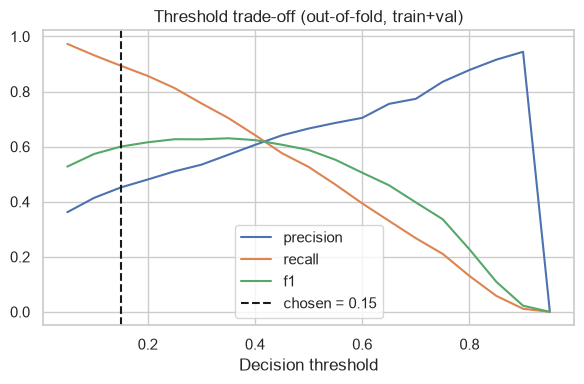

In [6]:
ev.plot_threshold_sweep(sweep, thr); plt.show()

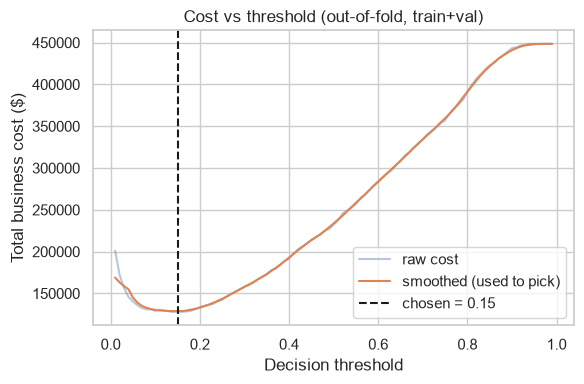

In [7]:
ev.plot_cost_curve(cost_df, thr); plt.show()

**The cost numbers are assumptions.** How much does the chosen threshold move if the real cost ratio differs?

In [8]:
display(cost_sensitivity(y_pool, p_pool).round(3))

,cost_fn,cost_fp,ratio,best_threshold,cost_at_threshold
0,150,50,3.0,0.22,100450.0
1,300,50,6.0,0.15,128700.0
2,500,50,10.0,0.07,145300.0
3,300,100,3.0,0.22,200900.0
4,300,150,2.0,0.35,251550.0


**Is the threshold choice stable?** Bootstrap the rows, re-pick the threshold each time, and compare the spread of the old method (validation only, raw argmin) with the one we use (pooled out-of-fold, smoothed). A smaller `std` / narrower `p10`–`p90` = more trustworthy.

In [9]:
stab = pd.DataFrame([
    {"method": "val only, raw argmin", **ev.threshold_stability(y_val, p_val["Improved"], COST_FN, COST_FP, N_BOOT, 0)},
    {"method": "pooled OOF, smoothed (used)", **ev.threshold_stability(y_pool, p_pool, COST_FN, COST_FP, N_BOOT, THRESH_SMOOTH)},
])
display(stab.round(3))

,method,n_rows,n_boot,median,p10,p90,std
0,"val only, raw argmin",1409,300,0.10,0.07,0.17,0.048
1,"pooled OOF, smoothed (used)",5634,300,0.15,0.11,0.16,0.019


## 5 · Test evaluation — run once, after all choices are frozen
No more tuning after this cell. (Caveat: the pipeline was re-run during development, so strictly the test set was seen more than once; see README §6.)

In [10]:
p_te = {"Baseline": baseline.predict_proba(X_test)[:, 1], "Improved": improved.predict_proba(X_test)[:, 1]}
results = pd.DataFrame([
    ev.summary(y_test, p_te["Baseline"], 0.5, "Baseline @0.5"),
    ev.summary(y_test, p_te["Baseline"], thr_base, "Baseline @cost-opt"),
    ev.summary(y_test, p_te["Improved"], 0.5, "Improved @0.5"),
    ev.summary(y_test, p_te["Improved"], thr, "Improved @cost-opt"),
])
display(results.round(3))
pred_opt = (p_te["Improved"] >= thr).astype(int)
print(ev.report(y_test, pred_opt, labels=["Stay", "Churn"]))

,model,threshold,roc_auc,pr_auc,precision,recall,f1
0,Baseline @0.5,0.50,0.843,0.631,0.657,0.537,0.591
1,Baseline @cost-opt,0.14,0.843,0.631,0.437,0.925,0.593
2,Improved @0.5,0.50,0.847,0.659,0.654,0.489,0.560
3,Improved @cost-opt,0.15,0.847,0.659,0.452,0.885,0.599


              precision    recall  f1-score   support

        Stay      0.936     0.613     0.741      1035
       Churn      0.452     0.885     0.599       374

    accuracy                          0.685      1409
   macro avg      0.694     0.749     0.670      1409
weighted avg      0.808     0.685     0.703      1409



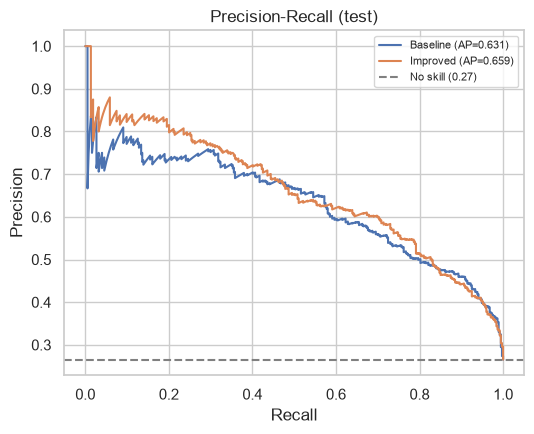

In [11]:
ev.plot_pr_curves(y_test, p_te); plt.show()

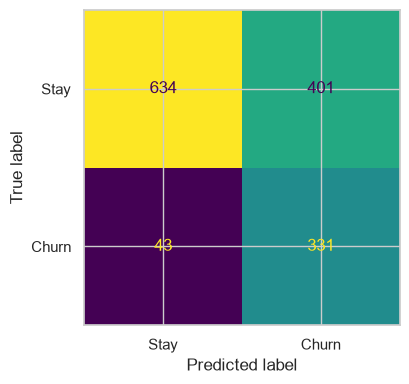

In [12]:
ev.plot_confusion(y_test, pred_opt, labels=["Stay", "Churn"]); plt.show()

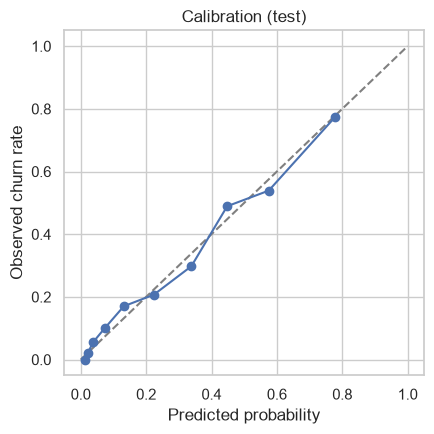

In [13]:
ev.plot_calibration(y_test, p_te["Improved"]); plt.show()

## 6 · Business impact on test
Total cost of each strategy under the stated cost assumptions. **Compare the two cost-optimal rows honestly:** is the 'improved' model actually cheaper than the baseline, or is the gap within noise?

In [14]:
n = len(y_test)
pred_base = (p_te["Baseline"] >= thr_base).astype(int)
business = pd.Series({
    "flag nobody": ev.total_cost(y_test, np.zeros(n, int), COST_FN, COST_FP),
    "flag everybody": ev.total_cost(y_test, np.ones(n, int), COST_FN, COST_FP),
    "XGBoost @ 0.5": ev.total_cost(y_test, (p_te["Improved"] >= 0.5).astype(int), COST_FN, COST_FP),
    f"XGBoost @ {thr:.2f} (cost-optimal)": ev.total_cost(y_test, pred_opt, COST_FN, COST_FP),
    f"LogReg baseline @ {thr_base:.2f} (cost-optimal)": ev.total_cost(y_test, pred_base, COST_FN, COST_FP),
}, name="total cost ($)")
display(business.to_frame())

,total cost ($)
flag nobody,112200.0
flag everybody,51750.0
XGBoost @ 0.5,62150.0
XGBoost @ 0.15 (cost-optimal),32950.0
LogReg baseline @ 0.14 (cost-optimal),30700.0


## Next
This notebook does **not** save anything except figures. To save the model + metadata + result tables run `python -m src.train` in the terminal (same code, same numbers), then open `03_explainability_errors.ipynb`.